# Milestone 3 - Task 2: Logistic Regression Baseline
## Objective
Train a Logistic Regression model as the baseline classifier using the updated feature set selected through the Milestone 3 feature selection experiment, while keeping the same target definition, train/test split, and preprocessing approach established in Task 1.

The model will be evaluated using:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

These results will provide a baseline for comparison with other classification models in Milestone 3.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Load Data and Recreate Shared Modeling Setup
Use the updated feature set selected through the Milestone 3 feature selection experiment, while keeping the same target definition, train/test split, and preprocessing approach established in Task 1.

In [2]:
# Load dataset
df = pd.read_csv("../data/kickstarter_us_filtered.csv")

# Binary target
df["success"] = (df["status"] == "successful").astype(int)

# Extract state from location
df["state"] = (
    df["location"]
    .str.rsplit(",", n=1)
    .str[-1]
    .str.strip()
)

# Updated selected feature set: added "updates"
numerical_features = ["goal", "duration", "levels", "updates"]
categorical_features = ["category", "subcategory", "state"]
selected_features = numerical_features + categorical_features

# Dataset for modeling
X = df[selected_features].copy()
y = df["success"].copy()

Note: updates is included based on Challenge Advisor guidance and the feature-selection experiment. For a true pre-launch production system, this feature would ideally represent planned updates or milestones available at launch.

In [3]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [4]:
# Preprocessing
numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [5]:
# Fit and transform the data accordingly
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [6]:
# Create a Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

In [7]:
# Train the model
logistic_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [8]:
# Make predictions on unseen test data
y_pred = logistic_model.predict(X_test_processed)

In [9]:
# Get predicted probabilities of class 1 (successful)
y_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

In [10]:
# Calculate all required metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

In [11]:
# Displaying the metrics results
print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy: 0.8025
Precision: 0.8203
Recall: 0.8185
F1 Score: 0.8194
ROC-AUC Score: 0.8804


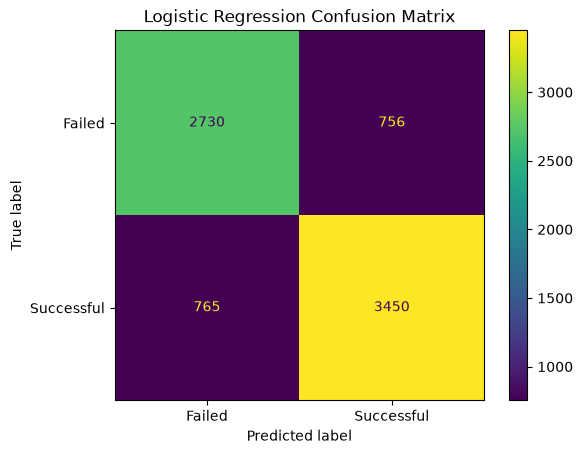

In [12]:
# Confusion Matrix to identify what kind of mistakes the model makes
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Failed", "Successful"]
)
disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## Findings
- The Logistic Regression baseline achieved **80.25% accuracy** and an **88.04% ROC-AUC score**.
- Precision (**82.03%**) was slightly higher than recall (**81.85%**), meaning the model was slightly better at making correct successful predictions than identifying all campaigns that actually succeeded.
- The **F1 score was 81.94%**, showing a strong balance between precision and recall.
- From the confusion matrix, the model correctly identified **3,450 successful campaigns** and **2,730 failed campaigns**.
- The model produced slightly more **false negatives (765)** than **false positives (756)**, which is consistent with precision being slightly higher than recall.